# Gradient boosted trees experiments

**Goal:** see whether gradient boosting beats the random forest hybrid, which is our best model so
far (`random_forest.ipynb` section 12).

**Where things stand:**
- On **unseen subjects** (E and J, 54% of test) nothing has beaten predicting all 1s: AdaBoost,
  random forest, Extra Trees and neural nets all fail. The features mostly identify subjects.
- On **known subjects** (A–M, 46% of test), per-subject normalisation plus the subject as a one-hot
  feature works. The forest reaches **0.867** test-weighted accuracy vs 0.843 for all 1s. The neural
  net got only 0.848.

**Why gradient boosting:** it is usually the strongest model family on tabular data. Unlike AdaBoost
it fits the gradient of the log-loss, so its probabilities are better and it is less sensitive to
noisy labels. It also has built-in regularisation (L2 on leaf values, minimum leaf size, feature
subsampling) and early stopping. We use scikit-learn's `HistGradientBoostingClassifier`, which works
like LightGBM.

Lab-notebook format: **hypothesis → code → result → interpretation** for each experiment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

## 1. Load data

In [2]:
train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")
sample_solution = pd.read_csv("sample_solution.csv")
print("Train shape:", train.shape)
print("Test shape :", test.shape)
train.output.value_counts(normalize=True)

Train shape: (4584, 670)
Test shape : (1732, 669)


output
1    0.844895
0    0.155105
Name: proportion, dtype: float64

## 2. Preprocessing

The same three feature sets as `random_forest.ipynb`:
- **raw**: one-hot `state`, drop `subject` and constant columns.
- **subject-norm**: every sensor column (`x*`, `y*`, `z*`) z-scored within its subject, using that
  subject's train and test rows (no labels).
- **subject-norm + subject id**: the above plus a one-hot of `subject`. This only makes sense for
  subjects that are also in the training data.

In [3]:
target = "output"
groups = train["subject"]
y = train[target]

def prep(df):
    X = df.drop(columns=[c for c in ["output", "subject"] if c in df])
    return pd.get_dummies(X, columns=["state"], dtype=int)

X_raw = prep(train)
X_test_raw = prep(test).reindex(columns=X_raw.columns, fill_value=0)
const_cols = X_raw.columns[X_raw.nunique() <= 1]
X_raw = X_raw.drop(columns=const_cols)
X_test_raw = X_test_raw.drop(columns=const_cols)
sensor_cols = [c for c in X_raw.columns if c[0] in "xyz" and c[1:].isdigit()]

both = pd.concat([X_raw, X_test_raw], ignore_index=True)
subj_all = pd.concat([train.subject, test.subject], ignore_index=True)
g = both[sensor_cols].groupby(subj_all.values)
both[sensor_cols] = ((both[sensor_cols] - g.transform("mean")) / g.transform("std").replace(0, np.nan)).fillna(0)
subj_onehot = pd.get_dummies(subj_all, prefix="subj", dtype=int).reindex(
    columns=[f"subj_{s}" for s in sorted(train.subject.unique())], fill_value=0)
both = pd.concat([both, subj_onehot], axis=1)
X_hyb = both.iloc[:len(train)].reset_index(drop=True)
X_test_hyb = both.iloc[len(train):].reset_index(drop=True)

known = test.subject.isin(train.subject.unique()).values
test_mix = test.subject[known].value_counts(normalize=True)
print(f"raw: {X_raw.shape[1]} features; hybrid: {X_hyb.shape[1]} features")
print(f"Known-subject test rows: {known.mean():.1%}")

raw: 564 features; hybrid: 575 features
Known-subject test rows: 45.7%


## 3. Evaluation harness

- `evaluate`: stratified 5-fold and GroupKFold-by-subject, as in the other notebooks, with AUC added.
- `known_subject_scores`: the hybrid scoring from `random_forest.ipynb` section 12. It uses
  stratified out-of-fold probabilities, tunes the threshold, and re-weights per-subject accuracy to
  the test mix of known subjects. The threshold is tuned on the same predictions it is scored on,
  so all of these numbers are slightly optimistic, equally for every model.

In [4]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gkf = GroupKFold(n_splits=5)
thresholds = np.linspace(0.3, 0.8, 51)
results = []

def evaluate(name, model, X):
    row = {"model": name}
    for cv_name, cv, kw in [("strat", skf, {}), ("group", gkf, {"groups": groups})]:
        s = cross_validate(model, X, y, cv=cv, scoring=["accuracy", "f1_macro", "roc_auc"], **kw)
        row[f"{cv_name}_acc"] = s["test_accuracy"].mean()
        row[f"{cv_name}_f1m"] = s["test_f1_macro"].mean()
        row[f"{cv_name}_auc"] = s["test_roc_auc"].mean()
    results.append(row)
    return pd.Series(row)

def test_weighted_acc(pred):
    per_subj = pd.Series(pred == y.values).groupby(groups.values).mean()
    return (per_subj.reindex(test_mix.index) * test_mix).sum()

def known_subject_scores(p):
    accs = [accuracy_score(y, (p >= t).astype(int)) for t in thresholds]
    t = thresholds[int(np.argmax(accs))]
    pred = (p >= t).astype(int)
    return {"threshold": t, "strat_acc": accuracy_score(y, pred),
            "f1_macro": f1_score(y, pred, average="macro"), "auc": roc_auc_score(y, p),
            "test_weighted_acc": test_weighted_acc(pred)}

def oof(model, X):
    return cross_val_predict(model, X, y, cv=skf, method="predict_proba")[:, 1]

evaluate("majority baseline", DummyClassifier(strategy="most_frequent"), X_raw)

model        majority baseline
strat_acc             0.844895
strat_f1m             0.457964
strat_auc                  0.5
group_acc             0.852051
group_f1m              0.45784
group_auc                  0.5
dtype: object

## 4. Experiment 1: gradient boosting on unseen subjects (raw features)

**Hypothesis:** boosting will do no better than every other model on unseen subjects. Its
stratified score may be the best yet, but grouped accuracy will be at or below the baseline,
because the problem is the features, not the model.

In [5]:
def hgb(**kw):
    params = dict(learning_rate=0.05, max_iter=1000, early_stopping=True, validation_fraction=0.1,
                  n_iter_no_change=30, random_state=RANDOM_STATE)
    return HistGradientBoostingClassifier(**{**params, **kw})

evaluate("hgb default, raw", hgb(), X_raw)
pd.DataFrame(results).set_index("model").round(4)

,strat_acc,strat_f1m,strat_auc,group_acc,group_f1m,group_auc
model,,,,,,
majority baseline,0.8449,0.4580,0.5000,0.8521,0.4578,0.5000
"hgb default, raw",0.8471,0.5193,0.7432,0.8474,0.4611,0.5421


**Interpretation:** the hypothesis held. Boosting has the best stratified AUC of any model on raw
features (0.74), but on unseen subjects it falls to 0.54 AUC and 0.847 accuracy, below the baseline
(0.852). Gradient boosting fails on unseen subjects in the same way as every other model. Everything
below is about known subjects only.

## 5. Experiment 2: gradient boosting in the hybrid setup (known subjects)

**Hypothesis:** on the subject-normalised + subject-id features, boosting will beat the forest's
0.867. Boosting builds each tree to fix the previous trees' errors, so it should pick up the
within-subject signal in G, M, L and B that the forest found, and sharpen it.

As a check, we recompute the forest hybrid with exactly the same features and folds. It should
reproduce 0.867.

In [6]:
rf = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE)
p_rf = oof(rf, X_hyb)
p_hgb = oof(hgb(), X_hyb)

known_rows = {"all 1s": {"threshold": np.nan, "strat_acc": (y == 1).mean(), "f1_macro": 0.458, "auc": 0.5,
                         "test_weighted_acc": test_weighted_acc(np.ones(len(y), dtype=int))},
              "random forest": known_subject_scores(p_rf),
              "hgb default": known_subject_scores(p_hgb)}
pd.DataFrame(known_rows).T.round(4)

,threshold,strat_acc,f1_macro,auc,test_weighted_acc
all 1s,NaN,0.8449,0.4580,0.500,0.8426
random forest,0.58,0.8695,0.7212,0.865,0.8666
hgb default,0.56,0.8656,0.6828,0.854,0.8626


**Interpretation:** the hypothesis was wrong. Untuned boosting (0.863 test-weighted, macro-F1 0.68)
is **slightly worse than the forest** (0.867, 0.72), and its AUC is lower too (0.854 vs 0.865). The
forest check reproduces `random_forest.ipynb` exactly (0.8666), so the comparison is fair. With
only ~700 class-0 rows spread over 11 subjects, averaging many deep trees (bagging) seems to suit this
data better than building trees one after another to correct each other (boosting).

## 6. Experiment 3: tune tree size, L2 and feature subsampling

**Hypothesis:** with 575 features, about 4.6k rows and only ~700 class-0 rows, smaller trees
(`max_leaf_nodes`), L2 on leaf values (`l2_regularization`) and per-split feature subsampling
(`max_features`) will each reduce overfitting. Feature subsampling should help most, because it is
what lets the forest use many weak features rather than a few strong ones. The learning rate is
fixed at 0.05; early stopping chooses the number of trees.

In [7]:
grid = []
for leaves in [7, 31]:
    for l2 in [0.0, 1.0]:
        for mf in [1.0, 0.3]:
            p = oof(hgb(max_leaf_nodes=leaves, l2_regularization=l2, max_features=mf), X_hyb)
            grid.append({"max_leaf_nodes": leaves, "l2_regularization": l2, "max_features": mf,
                         **known_subject_scores(p), "_p": p})
grid = pd.DataFrame(grid)
grid.drop(columns="_p").sort_values("test_weighted_acc", ascending=False).round(4)

,max_leaf_nodes,l2_regularization,max_features,threshold,strat_acc,f1_macro,auc,test_weighted_acc
7,31,1.0,0.3,0.61,0.8665,0.7002,0.8561,0.8640
4,31,0.0,1.0,0.56,0.8656,0.6828,0.8540,0.8626
6,31,1.0,1.0,0.64,0.8647,0.7155,0.8543,0.8621
5,31,0.0,0.3,0.62,0.8630,0.6950,0.8555,0.8603
3,7,1.0,0.3,0.54,0.8604,0.6570,0.8400,0.8578
1,7,0.0,0.3,0.57,0.8582,0.6689,0.8434,0.8556
0,7,0.0,1.0,0.54,0.8582,0.6451,0.8412,0.8555
2,7,1.0,1.0,0.55,0.8571,0.6498,0.8410,0.8545


In [8]:
best = grid.loc[grid.test_weighted_acc.idxmax()]
best_params = dict(max_leaf_nodes=int(best.max_leaf_nodes), l2_regularization=best.l2_regularization,
                   max_features=best.max_features)
p_hgb_best = best["_p"]
print("Best:", best_params)

Best: {'max_leaf_nodes': 31, 'l2_regularization': np.float64(1.0), 'max_features': np.float64(0.3)}


**Interpretation:** part of the hypothesis held. **Bigger trees (31 leaves) are better than small
ones (7) in every combination**, by about 0.5–1 pt. That is the opposite of "smaller trees reduce
overfitting": the within-subject signal needs feature interactions. L2 plus feature subsampling
together give the best setting (0.864), but the top four settings are within 0.004 of each other.
That is about the size of the threshold-tuning noise, so this tuning doesn't separate the
settings. The tuned model still doesn't beat the forest (0.867).

## 7. Experiment 4: blend boosting and forest

**Hypothesis:** boosting and bagging make different kinds of errors (bias vs variance). Averaging
their probabilities should beat either one alone, if they disagree enough on known-subject rows.

In [9]:
p_blend = (p_rf + p_hgb_best) / 2
known_rows["hgb tuned " + str(best_params)] = known_subject_scores(p_hgb_best)
known_rows["blend rf + hgb tuned"] = known_subject_scores(p_blend)
print(f"Correlation of rf and hgb OOF probabilities: {np.corrcoef(p_rf, p_hgb_best)[0, 1]:.3f}")
known_table = pd.DataFrame(known_rows).T
known_table.round(4)

Correlation of rf and hgb OOF probabilities: 0.898


,threshold,strat_acc,f1_macro,auc,test_weighted_acc
all 1s,NaN,0.8449,0.4580,0.5000,0.8426
random forest,0.58,0.8695,0.7212,0.8650,0.8666
hgb default,0.56,0.8656,0.6828,0.8540,0.8626
"hgb tuned {'max_leaf_nodes': 31, 'l2_regularization': np.float64(1.0), 'max_features': np.float64(0.3)}",0.61,0.8665,0.7002,0.8561,0.8640
blend rf + hgb tuned,0.58,0.8722,0.7121,0.8675,0.8695


Best for known subjects: blend rf + hgb tuned (threshold 0.58)


,A,B,C,D,F,G,H,I,K,L,M
acc,0.971,0.871,0.759,0.938,0.809,0.645,0.862,0.962,1.000,0.939,0.765
rf_acc,0.971,0.883,0.748,0.938,0.791,0.635,0.862,0.962,0.996,0.941,0.758
all_1s_acc,0.971,0.860,0.756,0.938,0.779,0.492,0.862,0.962,1.000,0.912,0.709
test_share,0.075,0.099,0.090,0.105,0.076,0.111,0.042,0.157,0.087,0.090,0.070


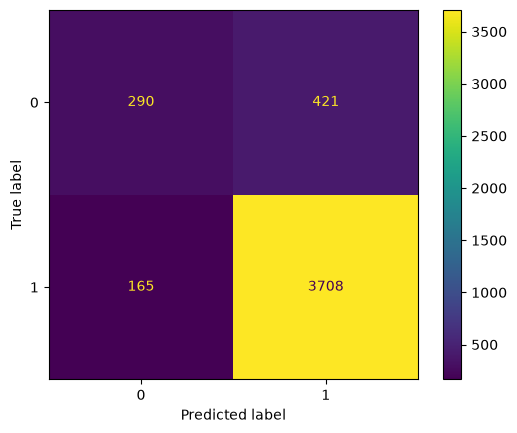

In [10]:
final_name = known_table.drop("all 1s").test_weighted_acc.astype(float).idxmax()
p_final = {"random forest": p_rf, "hgb default": p_hgb, "blend rf + hgb tuned": p_blend}.get(final_name, p_hgb_best)
t_final = known_table.loc[final_name, "threshold"]
print(f"Best for known subjects: {final_name} (threshold {t_final:.2f})")
pred = (p_final >= t_final).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y, pred)).plot()
pd.DataFrame({"acc": pd.Series(pred == y.values).groupby(groups.values).mean(),
              "rf_acc": pd.Series((p_rf >= known_table.loc["random forest", "threshold"]).astype(int) == y.values)
                        .groupby(groups.values).mean(),
              "all_1s_acc": (y == 1).groupby(groups.values).mean(),
              "test_share": test_mix}).round(3).T

**Interpretation:** the blend is the **best known-subject model so far**: 0.8695 test-weighted
(forest 0.8666, boosting 0.8640) and the best AUC (0.868). It gains on F (+1.8 pts vs the forest),
M, C, G and K, and loses a little on B and L. The improvement is small, though: +0.3 pts on
known-subject rows, so about **+0.1 pts overall**. The two models' probabilities are 0.90
correlated, so they mostly make the same mistakes. Treat the blend as equal to or slightly better
than the forest, not a clear step up.

## 8. Feature importance (known-subject model)

`HistGradientBoostingClassifier` has no impurity importance, so we use **permutation importance**
on one stratified validation fold, scored by AUC. (Accuracy hardly changes when a model rarely
predicts class 0, which is why we use AUC.)

**Hypothesis:** the subject one-hot columns will rank high, since each subject's class-0 rate is
learnable, and a small group of normalised sensor features will carry the within-subject signal.

Subject columns in top 20: ['subj_G', 'subj_K']
Features with importance > 0.002: 8


z47       0.0113
x40       0.0106
phase     0.0071
y8        0.0061
y101      0.0051
y116      0.0041
z117      0.0038
subj_G    0.0035
x47       0.0018
subj_K    0.0018
dtype: float64

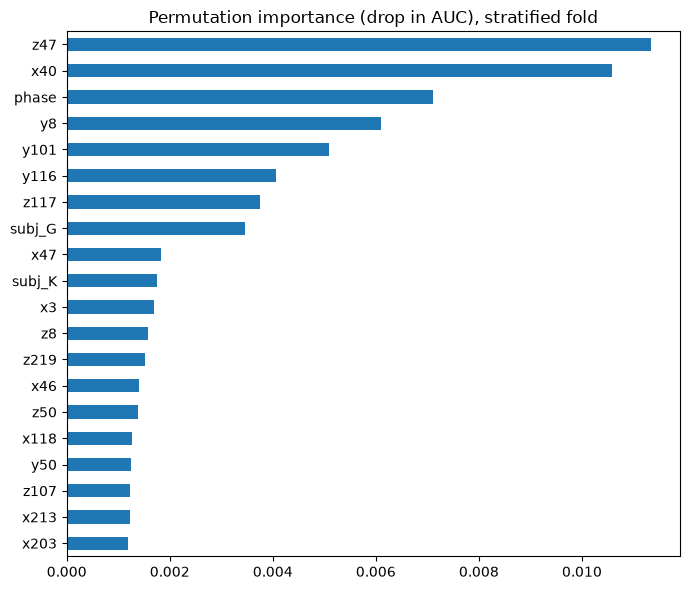

In [11]:
tr_idx, va_idx = next(skf.split(X_hyb, y))
imp_model = hgb(**best_params).fit(X_hyb.iloc[tr_idx], y.iloc[tr_idx])
perm = permutation_importance(imp_model, X_hyb.iloc[va_idx], y.iloc[va_idx], scoring="roc_auc",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_hyb.columns).sort_values(ascending=False)
perm_imp.head(20)[::-1].plot.barh(figsize=(7, 6), title="Permutation importance (drop in AUC), stratified fold")
plt.tight_layout()
print("Subject columns in top 20:", [c for c in perm_imp.head(20).index if c.startswith("subj_")])
print(f"Features with importance > 0.002: {(perm_imp > 0.002).sum()}")
perm_imp.head(10).round(4)

**Interpretation:** the hypothesis held in part. Only **8 features** lower AUC by more than 0.002
when shuffled, so the known-subject signal is concentrated in a few features:
- The top features are sensor readings normalised within subject: **`z47`** and **`x40`** (each
  about 0.011 AUC), then `y8`, `y101`, `y116` and `z117`.
- **`phase`** is third (0.007). That fits the training data, where class-0 rates differ by phase
  (`train.groupby("phase").output.mean()`) (17–20% in phases 1–2 vs 12–13% in phases 3–4).
- Only two subject columns make the top 20: **`subj_G`** (the subject with the most class 0) and
  **`subj_K`** (no class 0 at all). The model uses subject id mostly to mark these two extremes.

`z47` and `x40` are good candidates for a SHAP or per-subject plot to show the direction of their
effect.

## 9. Hybrid submission

Fit the best known-subject model on all training rows, predict the known-subject test rows with its
tuned threshold, and set E and J to 1.

In [12]:
def fit_proba(name):
    hgb_final = hgb(**best_params) if "tuned" in name else hgb()
    if name == "random forest":
        return rf.fit(X_hyb, y).predict_proba(X_test_hyb[known])[:, 1]
    if name.startswith("blend"):
        return (rf.fit(X_hyb, y).predict_proba(X_test_hyb[known])[:, 1]
                + hgb_final.fit(X_hyb, y).predict_proba(X_test_hyb[known])[:, 1]) / 2
    return hgb_final.fit(X_hyb, y).predict_proba(X_test_hyb[known])[:, 1]

gb_hybrid = sample_solution.copy()
gb_hybrid["output"] = 1
gb_hybrid.loc[known, "output"] = (fit_proba(final_name) >= t_final).astype(int)
gb_hybrid.to_csv("submission_gb_hybrid.csv", index=False)

rf_hybrid = pd.read_csv("submission_hybrid.csv")
print(f"Predicted class 0: {(gb_hybrid.output[known] == 0).mean():.1%} of known-subject rows "
      f"(forest hybrid: {(rf_hybrid.output[known] == 0).mean():.1%})")
print(f"Agreement with the forest hybrid on known-subject rows: "
      f"{(gb_hybrid.output[known] == rf_hybrid.output[known]).mean():.1%}")
(gb_hybrid.output[known] == 0).groupby(test.subject[known].values).mean().round(3).rename("pred_frac_0")

Predicted class 0: 9.2% of known-subject rows (forest hybrid: 11.3%)
Agreement with the forest hybrid on known-subject rows: 96.2%


A    0.000
B    0.038
C    0.085
D    0.000
F    0.117
G    0.602
H    0.000
I    0.000
K    0.000
L    0.014
M    0.055
Name: pred_frac_0, dtype: float64

**Interpretation:** the blend predicts class 0 for **9.2%** of known-subject rows (forest: 11.3%)
and agrees with the forest hybrid on **96%** of them. Class-0 predictions are concentrated in G (60%,
below the forest's 74%, which section 13 of the forest notebook flagged as high), F (12%) and C (9%).
Because the blend is less extreme on G, it is a reasonable choice for the next submission. Expect a
public score within a few tenths of a point of the forest hybrid.

## Summary and next steps

**Result:**

| Known-subject model | Test-weighted acc | Macro-F1 | AUC |
|---|---|---|---|
| all 1s | 0.843 | 0.46 | 0.50 |
| neural net (`neural_net.ipynb` §11) | 0.848 | 0.57 | 0.78 |
| gradient boosting, tuned | 0.864 | 0.70 | 0.856 |
| random forest | 0.867 | 0.72 | 0.865 |
| **blend rf + hgb** | **0.870** | 0.71 | **0.868** |

On unseen subjects, gradient boosting fails the same way as the other models (grouped accuracy
0.847 vs 0.852 for all 1s).

**What we learned:**
- Boosting doesn't beat bagging on this data, even tuned. Bigger trees help, so the within-subject
  signal involves feature interactions.
- A forest + boosting blend is a little better than either model alone (+0.3 pts on known
  subjects), but the two are 0.90 correlated, so blending more tree models won't add much.
- The signal for known subjects comes mainly from `z47`, `x40` and `phase`, plus whether the
  subject is G or K.

**Submission:** `submission_gb_hybrid.csv` (blend for known subjects, 1 for E/J). It agrees with
`submission_hybrid.csv` on 96% of known-subject rows.

**Next steps:**
1. Submit it and compare its public score with the forest hybrid's. The CV difference is too small
   to be sure which is better without that.
2. **SHAP** on the blend's top features (`z47`, `x40`, `phase`) for the explainability part of the
   grade. `shap` isn't installed yet: `conda install -c conda-forge shap`.
3. Unseen subjects (54% of test) are still the main thing holding the score back. Model tuning won't
   fix that; it needs features that mean the same thing across subjects. One idea is to check
   whether `z47` and `x40` move in the same direction for class 0 in every subject.

*Runtime note:* the whole notebook runs in about 3.5 minutes.